# BiciTierra Market - Segmentacio

Objectiu: preparar una lectura útil de perfils de client abans de passar a un clustering més formal.

## Dades

Hi ha 2.000 clients sintètics, una fotografia de 30/06/2026 independent de la taula de vendes. Per a un clustering, excloeu identificador i data, escaleu magnituds i decidiu com tractar els nuls. `annual_spend`, `avg_order_value` i `orders_last_12m` tenen una relació aritmètica: usar-les totes pot donar massa pes al valor monetari. La segmentació per regles és només una referència.

## Ruta de treball

1. Triar variables rellevants per al valor del client.
2. Detectar casos amb dades absents o delicades.
3. Construir una segmentació simple orientada a negoci.
4. Escriure què validaries després amb clustering.

## 1. Revisió de qualitat

No val segmentar sense mirar abans si hi ha dades que exigixen tractament.

In [106]:
# > Carga los 2 000 clientes (foto del 30/06/2026).
from pathlib import Path
import pandas as pd

CUSTOMERS = Path('..') / 'data' / 'originales' / 'customers.csv'
customers = pd.read_csv(CUSTOMERS)
customers[['customer_id', 'annual_spend', 'orders_last_12m', 'returns_ratio', 'bike_interest']].head()

,customer_id,annual_spend,orders_last_12m,returns_ratio,bike_interest
0,C00001,4566.25,5,0.0000,electric
1,C00002,3835.08,6,0.0000,electric
2,C00003,1159.47,9,0.0000,urban
3,C00004,2702.07,9,0.1111,electric
4,C00005,304.05,3,0.0000,electric


In [107]:
# > Nulos por columna: hay que decidir qué hacer con ellos antes de segmentar.
customers.isna().sum().rename('nulls')

customer_id                  0
age                         20
city                         0
channel_preference           0
annual_spend                30
avg_order_value              0
orders_last_12m              0
returns_ratio                0
bike_interest                0
service_interest             0
snapshot_date                0
tenure_months                0
days_since_last_order       20
returned_orders_last_12m     0
Name: nulls, dtype: int64

In [108]:
# > Gasto: se reconstruye con su fórmula (avg_order_value × orders_last_12m).
# > Recencia: se rellena con la mediana, que no se deja arrastrar por los valores extremos.
customers['annual_spend'] = customers['annual_spend'].fillna(customers['avg_order_value'] * customers['orders_last_12m'])
customers['days_since_last_order'] = customers['days_since_last_order'].fillna(customers['days_since_last_order'].median())

In [109]:
# > Resumen numérico: el gasto está muy sesgado (pocos clientes gastan mucho).
customers[['annual_spend', 'avg_order_value', 'orders_last_12m', 'returns_ratio']].describe().round(2)

,annual_spend,avg_order_value,orders_last_12m,returns_ratio
count,2000.00,2000.00,2000.00,2000.00
mean,1381.66,254.91,5.25,0.07
std,1618.98,266.43,2.99,0.13
min,35.31,19.06,1.00,0.00
25%,323.12,93.96,3.00,0.00
50%,766.71,145.56,5.00,0.00
75%,1876.86,289.39,7.00,0.10
max,13968.60,1898.82,17.00,1.00


## 2. Segmentació simple orientada a negoci

Mentres no usem clustering formal, podem construir una primera lectura amb regles transparents.

In [110]:
# > Segmentación por reglas fijas: es solo la referencia para comparar con K-Means.
def simple_segment(row):
    if row['annual_spend'] >= 3000 and row['returns_ratio'] <= 0.02:
        return 'premium'
    if row['annual_spend'] >= 1200 and row['orders_last_12m'] >= 8:
        return 'valor_mitja_alt'
    return 'ocasional_o_baix_valor'

customers['simple_segment'] = customers.apply(simple_segment, axis=1)
customers[['customer_id', 'annual_spend', 'orders_last_12m', 'returns_ratio', 'simple_segment']].sort_values(['simple_segment', 'annual_spend'], ascending=[True, False])


,customer_id,annual_spend,orders_last_12m,returns_ratio,simple_segment
1705,C01706,6969.83,7,0.1429,ocasional_o_baix_valor
1071,C01072,6902.40,6,0.1667,ocasional_o_baix_valor
1912,C01913,6602.45,5,0.2000,ocasional_o_baix_valor
1034,C01035,6226.98,6,0.1667,ocasional_o_baix_valor
801,C00802,6005.16,7,0.1429,ocasional_o_baix_valor
...,...,...,...,...,...
1651,C01652,1230.32,8,0.2500,valor_mitja_alt
8,C00009,1219.52,8,0.0000,valor_mitja_alt
915,C00916,1212.24,8,0.1250,valor_mitja_alt
850,C00851,1204.24,8,0.0000,valor_mitja_alt


In [111]:
# > Cuántos clientes caen en cada segmento de las reglas.
customers['simple_segment'].value_counts().rename_axis('segment').to_frame('clients')

,clients
segment,
ocasional_o_baix_valor,1532
valor_mitja_alt,288
premium,180


## 3. Lectura per segment

Si la segmentació no permet una interpretació comercial, encara no està madura.

In [112]:
# > Medias de cada segmento de las reglas, para ver si tienen sentido comercial.
customers.groupby('simple_segment')[['annual_spend', 'avg_order_value', 'orders_last_12m', 'returns_ratio']].mean().round(2)

,annual_spend,avg_order_value,orders_last_12m,returns_ratio
simple_segment,,,,
ocasional_o_baix_valor,808.55,198.05,4.18,0.07
premium,4808.45,774.41,6.71,0.00
valor_mitja_alt,2288.55,232.69,10.02,0.07


## 4. Què faltaria validar amb clustering real

- si els grups continuen apareixent sense regles manuals
- si hi ha clients sorollosos o fronterers
- si la lectura comercial es manté quan passem a un algorisme de segmentació

In [113]:
# > Correlación entre variables: si dos dicen lo mismo, no conviene usar las dos.
customers[['annual_spend','orders_last_12m','days_since_last_order','returns_ratio']].corr().round(2)

,annual_spend,orders_last_12m,days_since_last_order,returns_ratio
annual_spend,1.00,0.46,-0.17,-0.08
orders_last_12m,0.46,1.00,-0.39,0.02
days_since_last_order,-0.17,-0.39,1.00,-0.04
returns_ratio,-0.08,0.02,-0.04,1.00


## 5. Semana 4 · Clustering con K-Means

La segmentación por reglas de arriba es solo la referencia. Ahora buscamos grupos sin fijar umbrales a mano.

**Preparación**

- **Nulos:** los 30 `annual_spend` vacíos se reconstruyen como `avg_order_value × orders_last_12m`, que es su definición en el diccionario. Los 20 `days_since_last_order` vacíos se rellenan con la mediana; `age` no se usa.
- **Variables:** gasto anual (valor), pedidos (frecuencia), días desde el último pedido (recencia), ratio de devoluciones y antigüedad. Se excluyen `customer_id` y `snapshot_date`, que no describen el comportamiento, y `avg_order_value`, porque gasto = ticket × pedidos y usar las tres repetiría la misma información.
- **Escala:** gasto y pedidos están muy sesgados (gasto máximo de 13 969 € con una mediana de 758 €), así que se usa su logaritmo. Después se estandariza todo: K-Means mide distancias y, sin escalar, la variable en euros dominaría a las demás.

In [114]:
# > Preparación para K-Means: rellena nulos, pasa gasto y pedidos a logaritmo y escala todo.
# > Sin escalar, la variable en euros dominaría las distancias.
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

clientes = customers.copy()
# Reconstrucción justificada: annual_spend = avg_order_value × orders_last_12m
clientes['annual_spend'] = clientes['annual_spend'].fillna((clientes['avg_order_value'] * clientes['orders_last_12m']).round(2))
clientes['days_since_last_order'] = clientes['days_since_last_order'].fillna(clientes['days_since_last_order'].median())

X = pd.DataFrame({
    'log_gasto': np.log1p(clientes['annual_spend']),
    'log_pedidos': np.log1p(clientes['orders_last_12m']),
    'recencia_dias': clientes['days_since_last_order'],
    'ratio_devoluciones': clientes['returns_ratio'],
    'antiguedad_meses': clientes['tenure_months'],
})
Z = StandardScaler().fit_transform(X)
print('Nulos tras la preparación:', int(X.isna().sum().sum()))

Nulos tras la preparación: 0


### Elegir el número de grupos

Probamos de 2 a 7 grupos. La **inercia** (distancia dentro de los grupos) siempre baja al añadir grupos; buscamos dónde deja de bajar mucho. La **silueta** (de −1 a 1) mide si cada cliente está más cerca de su grupo que del siguiente.

In [115]:
# > Prueba de 2 a 7 grupos: inercia (menos es mejor, pero siempre baja) y silueta (más es mejor).
pruebas = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    pruebas.append({'k': k, 'inercia': round(km.inertia_), 'silueta': round(silhouette_score(Z, km.labels_), 3)})
pd.DataFrame(pruebas)

,k,inercia,silueta
0,2,7297,0.285
1,3,6251,0.210
2,4,5098,0.240
3,5,4317,0.252
4,6,3939,0.236
5,7,3627,0.239


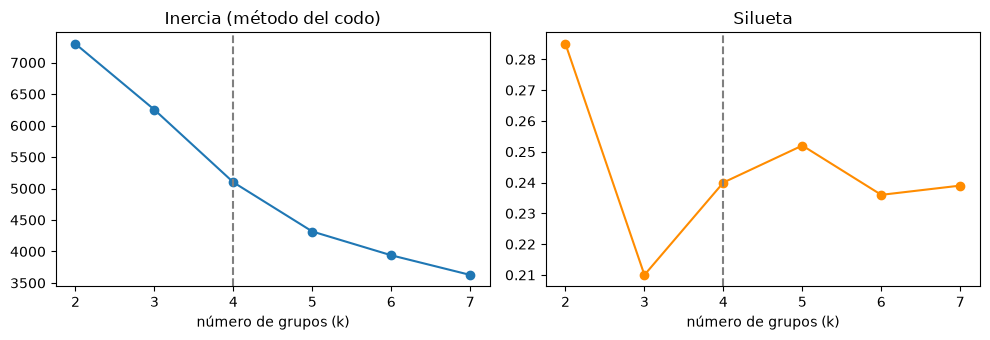

In [116]:
# > Gráfico de la tabla anterior: buscamos el «codo» de la inercia y una silueta alta.
import matplotlib.pyplot as plt

tabla_k = pd.DataFrame(pruebas)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(tabla_k['k'], tabla_k['inercia'], marker='o')
axes[0].set_title('Inercia (método del codo)')
axes[1].plot(tabla_k['k'], tabla_k['silueta'], marker='o', color='darkorange')
axes[1].set_title('Silueta')
for ax in axes:
    ax.axvline(4, color='grey', linestyle='--')
    ax.set_xlabel('número de grupos (k)')
plt.tight_layout()
plt.show()

Con 2 grupos la silueta es la más alta (0,285), pero solo separa clientes activos de inactivos, y eso ya lo hacen las reglas. Con **4 grupos** la inercia baja de forma clara (de 6 251 a 5 098) y la silueta mejora respecto a 3 grupos (de 0,21 a 0,24). Además, cada grupo tiene una lectura comercial distinta. Elegimos **k = 4**. Una silueta de 0,24 indica grupos con fronteras difusas: hay clientes entre dos grupos.

In [117]:
# > Ajusta K-Means con 4 grupos y pone nombre a cada uno según su perfil, no según su número.
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(Z)
clientes['cluster'] = km.labels_

perfil = clientes.groupby('cluster').agg(
    clientes=('customer_id', 'size'),
    gasto_mediano=('annual_spend', 'median'),
    pedidos_medianos=('orders_last_12m', 'median'),
    recencia_mediana=('days_since_last_order', 'median'),
    devoluciones_medias=('returns_ratio', 'mean'),
    antiguedad_mediana=('tenure_months', 'median'),
)
# Nombres asignados según el perfil, no según el número del grupo (que es arbitrario)
nombres = {}
nombres[perfil['devoluciones_medias'].idxmax()] = 'devoluciones_altas'
nombres[perfil.drop(index=list(nombres))['gasto_mediano'].idxmin()] = 'ocasionales_inactivos'
resto = perfil.drop(index=list(nombres))
nombres[resto['antiguedad_mediana'].idxmax()] = 'fieles_veteranos'
nombres[resto['antiguedad_mediana'].idxmin()] = 'nuevos_activos'
clientes['segmento'] = clientes['cluster'].map(nombres)
perfil.index = perfil.index.map(nombres)
perfil.round(2).sort_values('gasto_mediano', ascending=False)

,clientes,gasto_mediano,pedidos_medianos,recencia_mediana,devoluciones_medias,antiguedad_mediana
cluster,,,,,,
nuevos_activos,644,1456.22,6.0,33.0,0.05,31.0
fieles_veteranos,650,1349.59,6.0,30.5,0.05,92.0
devoluciones_altas,174,369.48,3.0,52.5,0.40,66.0
ocasionales_inactivos,532,216.45,2.0,113.5,0.00,63.0


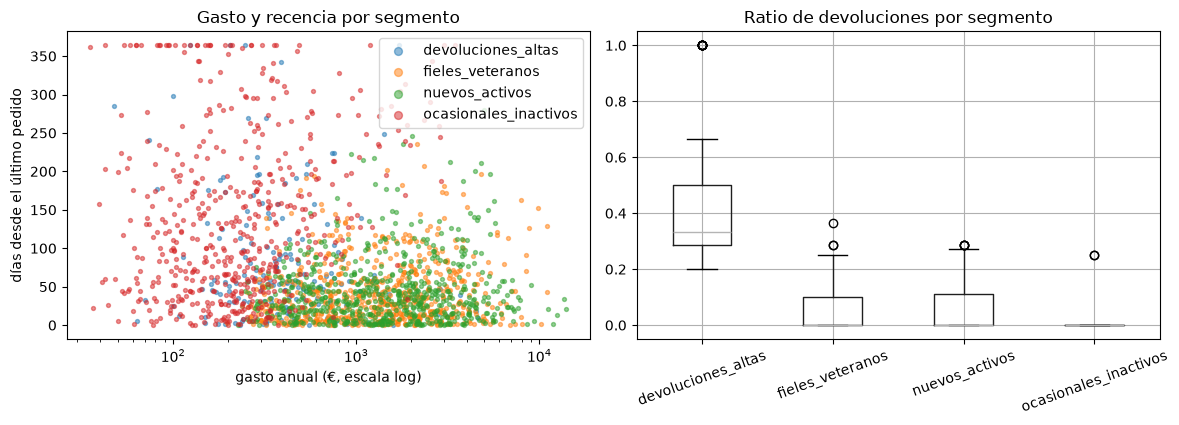

In [118]:
# > Gráfico: cada punto es un cliente, coloreado por segmento.
# > Gasto frente a días sin comprar; el ratio de devoluciones va aparte porque no se ve en estos dos ejes.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for seg, grupo in clientes.groupby('segmento'):
    axes[0].scatter(grupo['annual_spend'], grupo['days_since_last_order'], s=8, alpha=0.5, label=seg)
axes[0].set_xscale('log')
axes[0].set_xlabel('gasto anual (€, escala log)')
axes[0].set_ylabel('días desde el último pedido')
axes[0].set_title('Gasto y recencia por segmento')
axes[0].legend(markerscale=2)

clientes.boxplot(column='returns_ratio', by='segmento', ax=axes[1], rot=20)
axes[1].set_title('Ratio de devoluciones por segmento')
axes[1].set_xlabel('')
plt.suptitle('')
plt.tight_layout()
plt.show()

In [119]:
# > Qué tipo de bici interesa y qué canal prefiere cada segmento.
# Interés por tipo de bici y canal preferido en cada segmento (proporción de clientes)
pd.concat([pd.crosstab(clientes['segmento'], clientes['bike_interest'], normalize='index'),
           pd.crosstab(clientes['segmento'], clientes['channel_preference'], normalize='index')], axis=1).round(2)

,electric,mountain,service,urban,ecommerce,store
segmento,,,,,,
devoluciones_altas,0.15,0.27,0.14,0.44,0.59,0.41
fieles_veteranos,0.29,0.29,0.15,0.28,0.56,0.44
nuevos_activos,0.29,0.33,0.12,0.26,0.55,0.45
ocasionales_inactivos,0.18,0.21,0.29,0.32,0.56,0.44


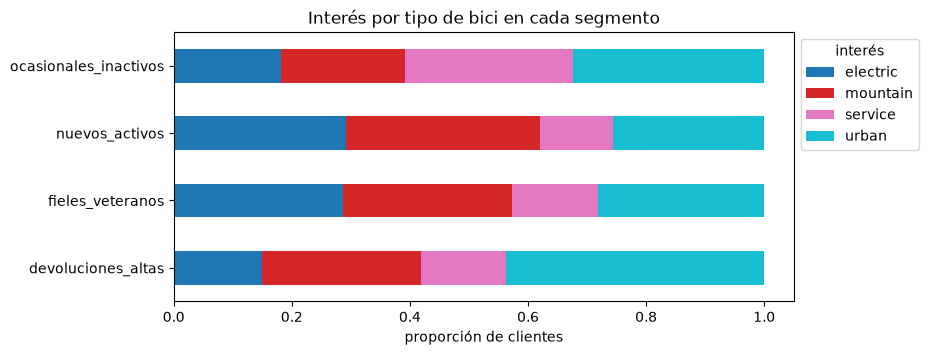

In [120]:
# > Gráfico: qué tipo de bici interesa a cada segmento (proporción de clientes).
pd.crosstab(clientes['segmento'], clientes['bike_interest'], normalize='index').plot(
    kind='barh', stacked=True, figsize=(8, 3.5), colormap='tab10')
plt.xlabel('proporción de clientes')
plt.ylabel('')
plt.title('Interés por tipo de bici en cada segmento')
plt.legend(title='interés', bbox_to_anchor=(1, 1))
plt.show()

### Casos fronterizos y comparación con las reglas

Un cliente es fronterizo si está casi a la misma distancia de dos centros. Lo medimos como la diferencia entre la distancia al segundo centro y al primero.

In [121]:
# > Clientes fronterizos: casi igual de cerca de dos grupos.
# > La tabla compara los segmentos de K-Means con los de las reglas.
distancias = np.sort(km.transform(Z), axis=1)
clientes['margen'] = distancias[:, 1] - distancias[:, 0]
print('Clientes fronterizos (margen < 0,25):', int((clientes['margen'] < 0.25).sum()), 'de', len(clientes))
pd.crosstab(clientes['segmento'], clientes['simple_segment'])

Clientes fronterizos (margen < 0,25): 270 de 2000


simple_segment,ocasional_o_baix_valor,premium,valor_mitja_alt
segmento,,,
devoluciones_altas,172,0,2
fieles_veteranos,425,80,145
nuevos_activos,405,98,141
ocasionales_inactivos,530,2,0


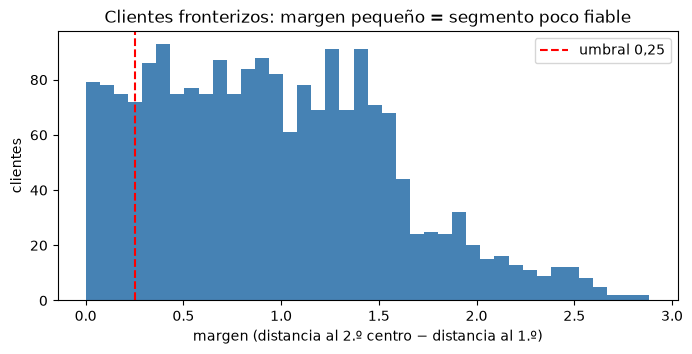

In [122]:
# > Gráfico: margen de cada cliente. A la izquierda de la línea roja están los fronterizos.
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(clientes['margen'], bins=40, color='steelblue')
ax.axvline(0.25, color='red', linestyle='--', label='umbral 0,25')
ax.set_xlabel('margen (distancia al 2.º centro − distancia al 1.º)')
ax.set_ylabel('clientes')
ax.set_title('Clientes fronterizos: margen pequeño = segmento poco fiable')
ax.legend()
plt.show()

In [123]:
# > Guarda el segmento de cada cliente y el perfil medio para el panel.
# Tabla de segmentos para el panel
clientes[['customer_id', 'segmento']].to_csv('../data/derivados/segmentos_clientes.csv', index=False)
perfil.round(2).to_csv('../evidencies/perfil_segmentos.csv')

### Perfiles

| Segmento | Clientes | Comportamiento | Diferencia clave |
|---|---|---|---|
| **Fieles veteranos** | 650 | Gasto mediano ~1 350 €, 6 pedidos al año, último pedido hace ~1 mes | Unos 8 años de antigüedad |
| **Nuevos activos** | 644 | Gasto mediano ~1 456 €, 6 pedidos, último pedido hace ~1 mes | Unos 2,5 años de antigüedad: valor alto, relación aún corta |
| **Ocasionales inactivos** | 532 | Gasto mediano ~216 €, 2 pedidos, último pedido hace casi 4 meses | Más interés en servicio técnico (29 %) que el resto |
| **Devoluciones altas** | 174 | Gasto mediano ~369 €, 3 pedidos | Devuelven el 40 % de los pedidos de media |

El canal preferido es parecido en todos los grupos (~56 % online), así que no separa perfiles.

**Casos fronterizos:** 270 clientes (13,5 %) están casi a la misma distancia de dos grupos. Su segmento es poco fiable y conviene no aplicarles acciones agresivas.

**Comparación con las reglas:** las reglas meten en `ocasional_o_baix_valor` a 1 532 clientes, incluidos más de 800 fieles y nuevos activos con gasto alto. K-Means separa a los inactivos de verdad (530 de 532 coinciden con las reglas) y descubre un grupo que las reglas no veían: el de devoluciones altas.

### Segmentos y acciones

| Segmento | Acción propuesta | Qué comprobar antes |
|---|---|---|
| Fieles veteranos | Programa de fidelidad: revisión anual gratuita y acceso anticipado a novedades | Que no compren igual sin el incentivo (probar con un grupo de control) |
| Nuevos activos | Bienvenida al segundo año: descuento en accesorios o paso a bici eléctrica | Que el margen aguante el descuento; medir si suben de antigüedad sin bajar el gasto |
| Ocasionales inactivos | Campaña de reactivación con el servicio técnico (puesta a punto) | El coste por cliente reactivado frente a su gasto bajo |
| Devoluciones altas | Revisar las causas (talla, producto, canal) y mejorar las fichas y el asesoramiento | Si las devoluciones se concentran en un producto o canal; no penalizar sin conocer la causa |

**Límites:** los datos son sintéticos y son una foto del 30/06/2026. No hay compras posteriores para comprobar si las acciones funcionan; habría que medirlo con una prueba real.